Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time

plt.style.use(['ggplot'])

Prediction Model

In [2]:
def model(w, x):

    ypred = np.dot(w, x)

    return ypred

Gradient of MSE

In [3]:
def grad_mse(w, xy):

    (x, y) = xy

    # Compute the output
    ypredicted = model(w, x)

    diff = y - ypredicted

    # this gives gradient of both w's
    grad = -np.dot(x, diff)

    return grad

Mean Squared Error

In [4]:
def mse(w, xy):

    (x, y) = xy

    xt = np.transpose(x)

    ypredicted = np.dot(w, x)

    loss = np.sum(
        (y - ypredicted) *
        (y - ypredicted)
    )

    m = 2 * len(y)

    loss = loss / m

    return loss

Gradient Descent

In [5]:
def gradient_descent(
    xy,
    max_iterations,
    w,
    obj_func,
    mse_func,
    grad_func,
    extra_param=[],
    learning_rate=0.05,
    momentum=0.8
):

    (x, y) = xy

    w_history = w
    f_history = obj_func(w, x)
    cost_history = mse_func(w, xy)

    delta_w = np.zeros(2)

    i = 0

    while i < max_iterations:

        delta_w = -learning_rate * grad_func(w, xy)

        w = w + delta_w

        # store the history of w and f
        w_history = np.vstack((w_history, w))

        ypredicted = obj_func(w, x)

        f_history = np.vstack((f_history, ypredicted))

        cost_history = np.vstack(
            (cost_history, mse_func(w, xy))
        )

        i = i + 1

    return w_history, f_history, cost_history

Create Test Data

In [6]:
ndim = 2

npoints = 3

w = np.array([0, 0])

myones = np.ones(npoints)

x = np.arange(0, npoints)

x = np.vstack((myones, x))

y = model(w, x)

y = y + 1

xy = (x, y)

print(xy)

(array([[1., 1., 1.],
       [0., 1., 2.]]), array([1., 1., 1.]))


Run Gradient Descent

In [7]:
max_iterations = 100

w_hist, f_hist, c_hist = gradient_descent(
    xy,
    max_iterations,
    w,
    model,
    mse,
    grad_mse,
    learning_rate=0.1,
    momentum=0.8
)

Inspect Results

In [8]:
print("Final Weights:")
print(w_hist[-1])

print("\nFinal Cost:")
print(c_hist[-1])

Final Weights:
[9.99895613e-01 7.52378090e-05]

Final Cost:
[2.31174358e-09]


View Weight History

In [9]:
print(w_hist)

[[0.00000000e+00 0.00000000e+00]
 [3.00000000e-01 3.00000000e-01]
 [4.20000000e-01 3.60000000e-01]
 [4.86000000e-01 3.54000000e-01]
 [5.34000000e-01 3.31200000e-01]
 [5.74440000e-01 3.05400000e-01]
 [6.10488000e-01 2.80368000e-01]
 [6.43231200e-01 2.57037600e-01]
 [6.73150560e-01 2.35549440e-01]
 [7.00540560e-01 2.15829552e-01]
 [7.25629526e-01 1.97752608e-01]
 [7.48614886e-01 1.81187446e-01]
 [7.69674186e-01 1.66009257e-01]
 [7.88969153e-01 1.52102373e-01]
 [8.06647696e-01 1.39360440e-01]
 [8.22845255e-01 1.27685912e-01]
 [8.37685905e-01 1.16989379e-01]
 [8.51283320e-01 1.07188918e-01]
 [8.63741648e-01 9.82094632e-02]
 [8.75156315e-01 8.99822371e-02]
 [8.85614749e-01 8.24442241e-02]
 [8.95197057e-01 7.55376873e-02]
 [9.03976634e-01 6.92097265e-02]
 [9.12020726e-01 6.34118731e-02]
 [9.19390946e-01 5.80997188e-02]
 [9.26143747e-01 5.32325756e-02]
 [9.32330850e-01 4.87731638e-02]
 [9.37999646e-01 4.46873269e-02]
 [9.43193554e-01 4.09437697e-02]
 [9.47952357e-01 3.75138186e-02]
 [9.523125

View Function History

In [10]:
print(f_hist)

[[0.         0.         0.        ]
 [0.3        0.6        0.9       ]
 [0.42       0.78       1.14      ]
 [0.486      0.84       1.194     ]
 [0.534      0.8652     1.1964    ]
 [0.57444    0.87984    1.18524   ]
 [0.610488   0.890856   1.171224  ]
 [0.6432312  0.9002688  1.1573064 ]
 [0.67315056 0.9087     1.14424944]
 [0.70054056 0.91637011 1.13219966]
 [0.72562953 0.92338213 1.12113474]
 [0.74861489 0.92980233 1.11098978]
 [0.76967419 0.93568344 1.1016927 ]
 [0.78896915 0.94107153 1.0931739 ]
 [0.8066477  0.94600814 1.08536858]
 [0.82284525 0.95053117 1.07821708]
 [0.8376859  0.95467528 1.07166466]
 [0.85128332 0.95847224 1.06566116]
 [0.86374165 0.96195111 1.06016057]
 [0.87515631 0.96513855 1.05512079]
 [0.88561475 0.96805897 1.0505032 ]
 [0.89519706 0.97073474 1.04627243]
 [0.90397663 0.97318636 1.04239609]
 [0.91202073 0.9754326  1.03884447]
 [0.91939095 0.97749066 1.03559038]
 [0.92614375 0.97937632 1.0326089 ]
 [0.93233085 0.98110401 1.02987718]
 [0.93799965 0.98268697 1.02

Plot Prediction Updates

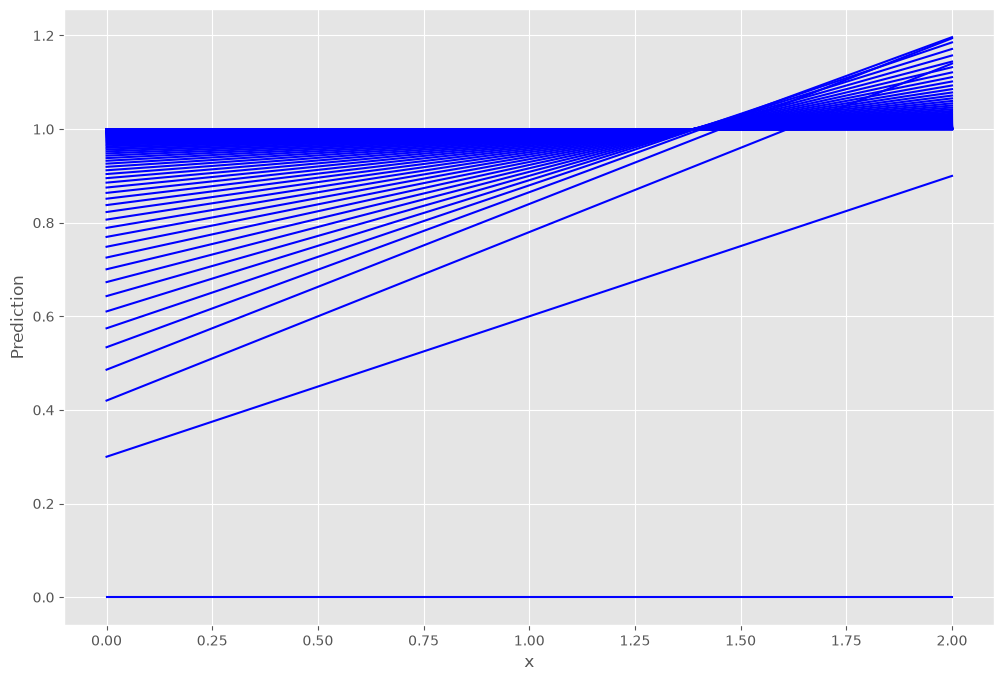

In [11]:
fig, ax = plt.subplots(figsize=(12, 8))

ax.set_ylabel('Prediction')
ax.set_xlabel('x')

for i in range(len(f_hist)):

    ax.plot(
        x[1],
        f_hist[i],
        'b'
    )

plt.show()

Plot Cost Function

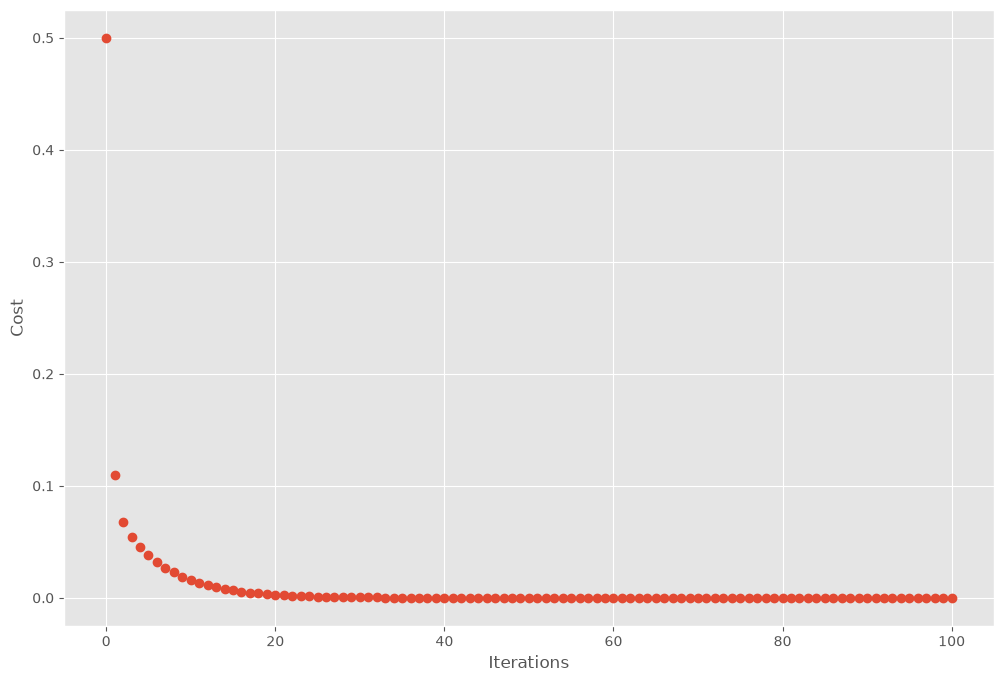

In [12]:
fig, ax = plt.subplots(figsize=(12, 8))

ax.set_ylabel('Cost')
ax.set_xlabel('Iterations')

iterations = len(c_hist)

ax.plot(
    range(iterations),
    c_hist,
    'o'
)

plt.show()

Check Convergence

In [13]:
print("Initial Cost:", c_hist[0])
print("Final Cost:", c_hist[-1])

Initial Cost: [0.5]
Final Cost: [2.31174358e-09]


Check Learned Parameters

In [14]:
print("Initial Weights:")
print(w_hist[0])

print("\nFinal Weights:")
print(w_hist[-1])

Initial Weights:
[0. 0.]

Final Weights:
[9.99895613e-01 7.52378090e-05]


New Function to Add

Add this as a new notebook cell after your gradient_descent() function.

In [15]:
def plot_GD(
    xy,
    w,
    max_iterations,
    learning_rate,
    ax,
    ax1=None
):

    x, y = xy

    y = model(w, x)

    xt = np.transpose(x)

    _ = ax.plot(x[1], y, 'b.')

    tr = 0.5

    for i in range(max_iterations):

        pred_prev = np.dot(w, x)

        w_hist, f_hist, c_hist = gradient_descent(
            xy,
            max_iterations - 1,
            w,
            model,
            mse,
            grad_mse,
            [],
            learning_rate=learning_rate,
            momentum=0.8
        )

        pred = model(w, x)

        if (i % 2 == 0):

            ypred = f_hist[i]

            _ = ax.plot(
                x[1],
                ypred,
                'b-',
                alpha=tr
            )

            if tr < 0.8:
                tr = tr + 0.2

        if ax1 is not None:

            _ = ax1.plot(
                range(max_iterations),
                c_hist,
                'o'
            )

Comparison Cell

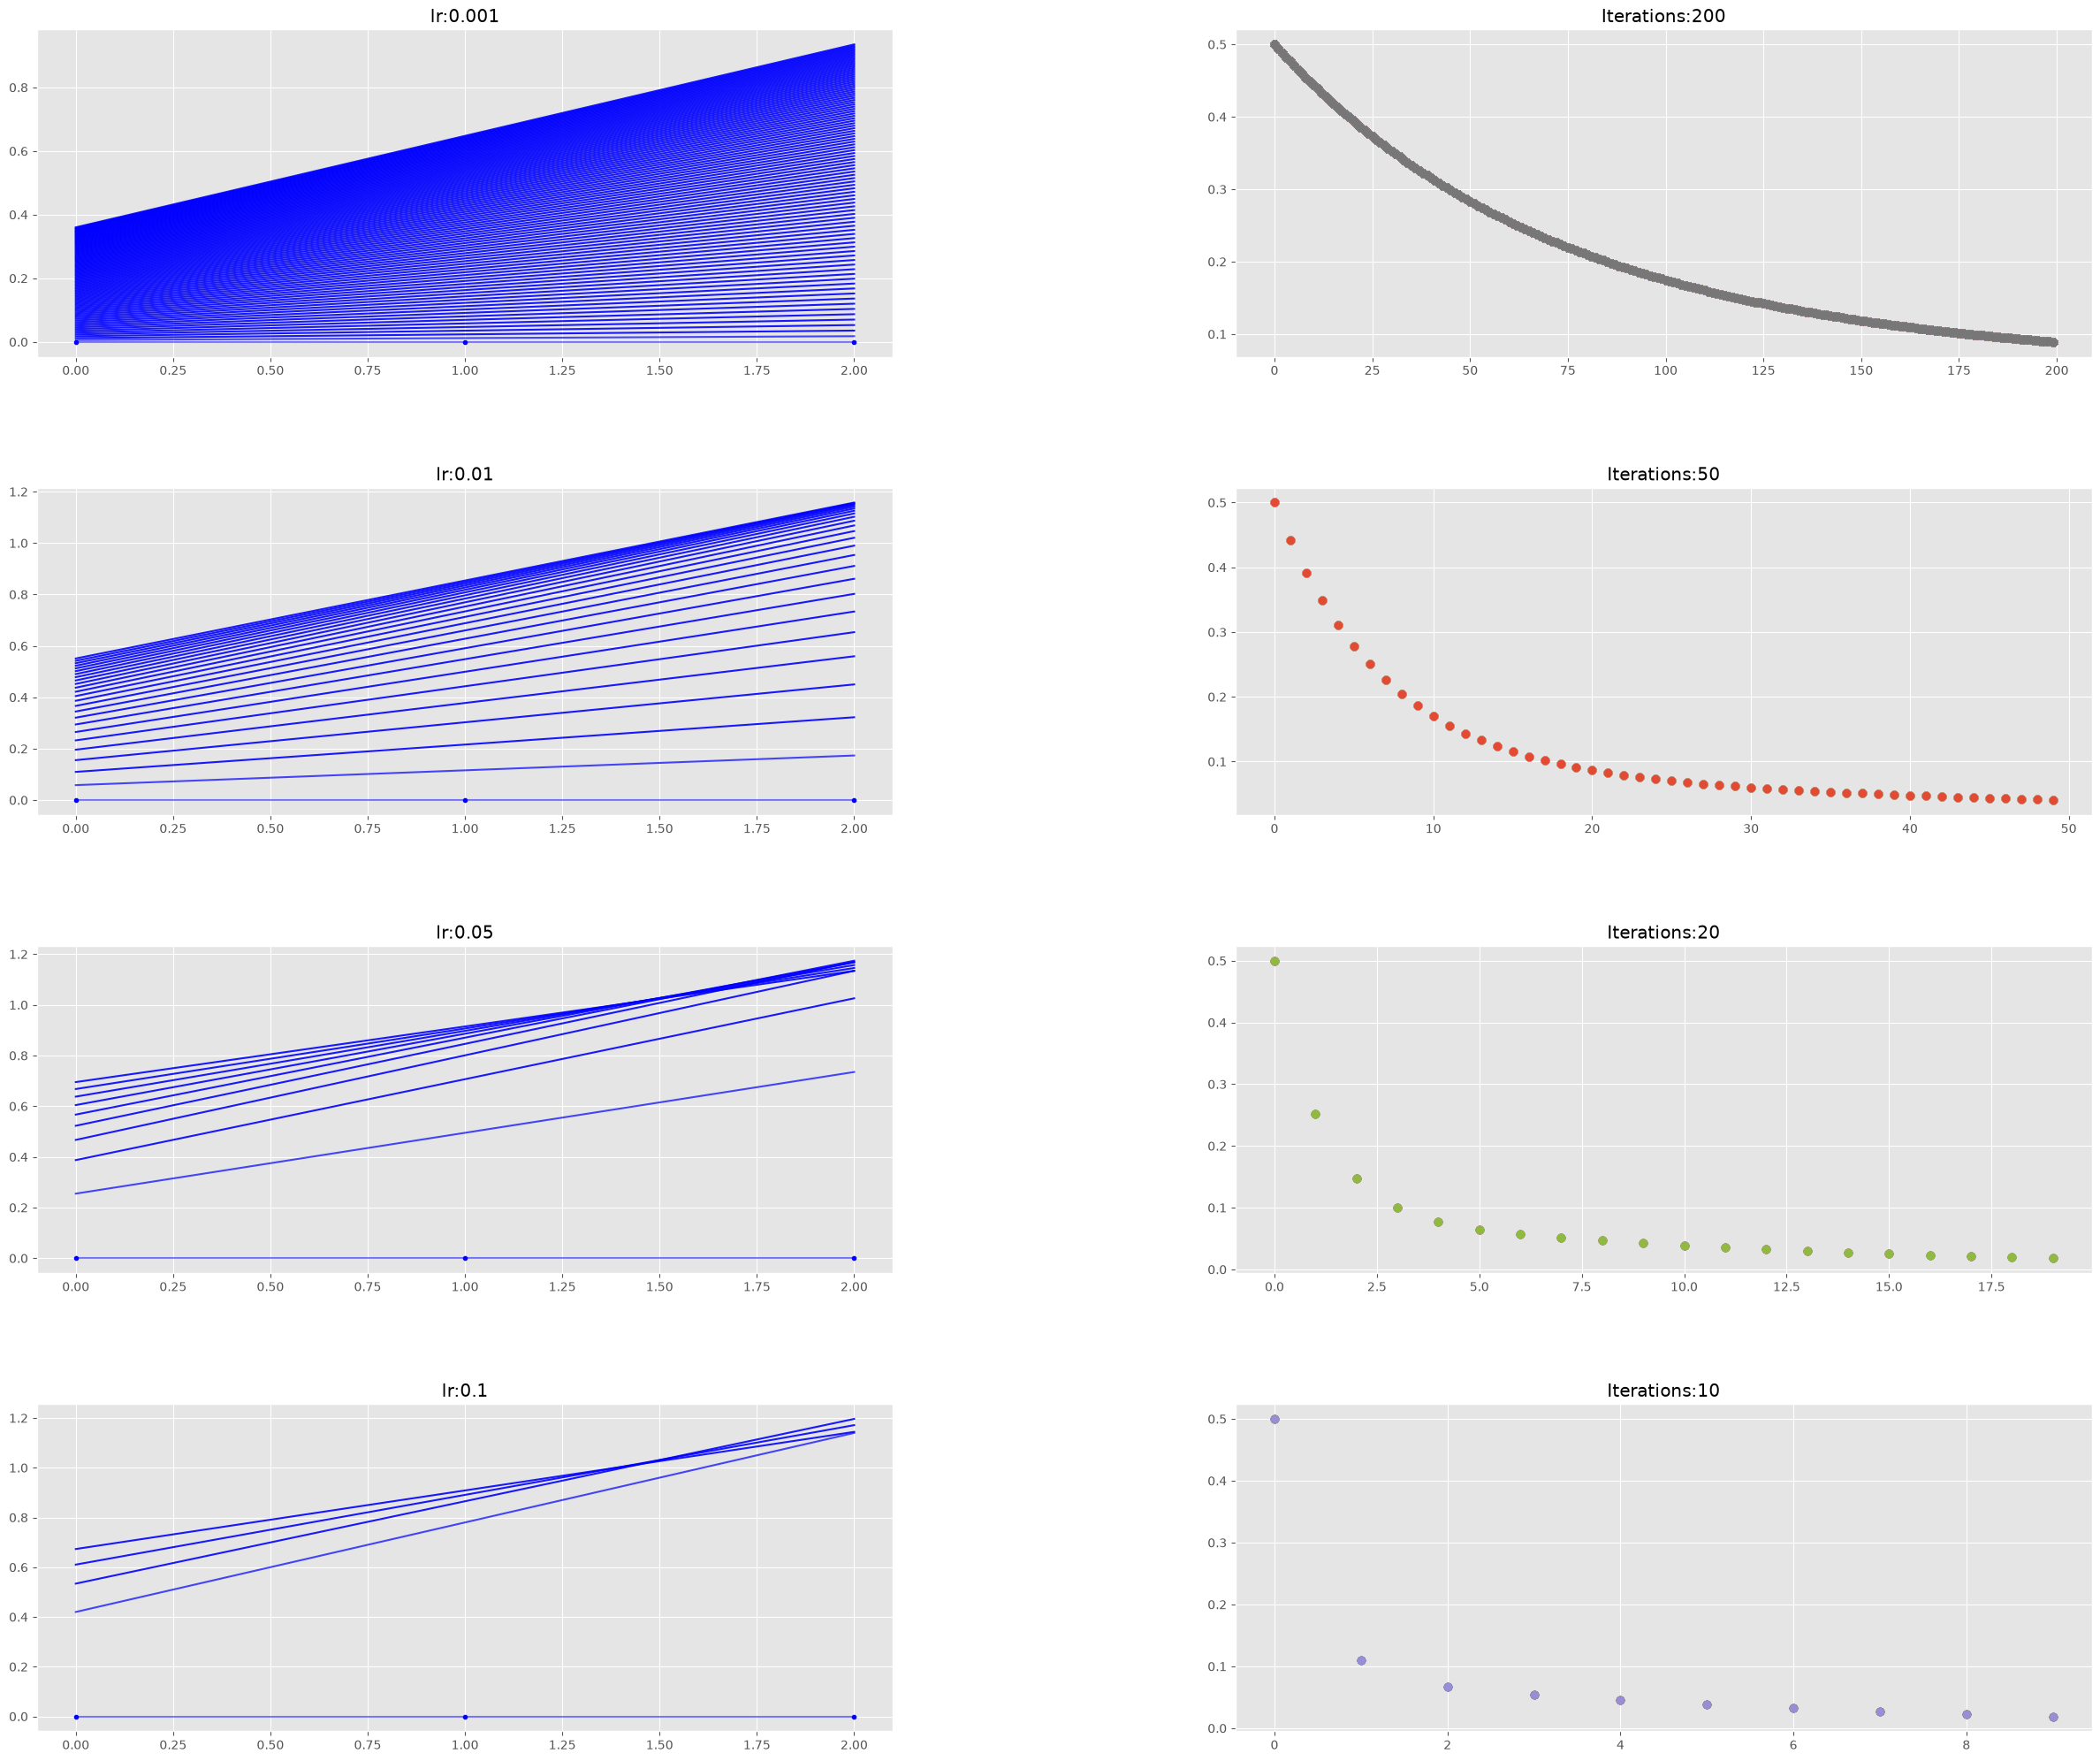

In [16]:
fig = plt.figure(figsize=(30, 25))

fig.subplots_adjust(
    hspace=0.4,
    wspace=0.4
)

w = np.array([0, 0])

it_lr = [
    (200, 0.001),
    (50, 0.01),
    (20, 0.05),
    (10, 0.1)
]

count = 0

for n_iter, lr in it_lr:

    count += 1

    ax = fig.add_subplot(
        4,
        2,
        count
    )

    count += 1

    ax1 = fig.add_subplot(
        4,
        2,
        count
    )

    ax.set_title(
        "lr:{}".format(lr)
    )

    ax1.set_title(
        "Iterations:{}".format(n_iter)
    )

    plot_GD(
        xy,
        w,
        n_iter,
        lr,
        ax,
        ax1
    )

plt.show()